# Stage 9b: Dynamic selection over 50 reranked candidates, and freezing one cutoff

**Why this notebook.** Notebook 09 (branch `worktree-agent-a5fcabd5366536ab4`) reranked the top 30 fused candidates
with MiniLM and tuned a score cutoff (keep every candidate scoring ≥ cutoff, clamped to 3–15 kept). Its cutoff
−3.68 matched fixed top 10 in-sample but fell short under cross-validation. This notebook extends it in three ways:

1. **50 candidates.** MiniLM scores the top **50** fused candidates per question (once, cached), so a dynamic rule
   can reach chunks that fall outside the top 30 fused.
2. **Recall against chunks kept, everywhere.** Instead of one tuned point, both families are drawn as curves:
   fixed top k (k = 1…15) and the dynamic cutoff over its whole range. They are compared at the same average
   number of chunks, in-sample and then cross-validated.
3. **One frozen cutoff.** A selection rule is written down *before* any cross-validated number is computed, then
   applied to all 40 questions. The result is saved to `evals/frozen_dynamic_selection.json` and will run as its own
   system in the final end-to-end comparison. It must not be retuned after that.

**Metric.** Chunk recall as in notebook 08 (`evaluation.chunk_recall`), with k = the number kept for that
question, averaged over the 40 questions of `evals/handbook_eval.jsonl`. "Chunks kept" counts kept items (an image
record counts as one, as in the eval). The context budget is measured in mean chunks kept, not tokens; tokens are
shown for reference.

**Model cost is the same for every rule here**: all of them rerank the same 50 candidates. They differ only in how
many of those are passed on.

In [1]:
import sys
from pathlib import Path

# Use this worktree's copy of the package, not the editable install from the main repo.
WORKTREE = Path.cwd().resolve().parent
WORKTREE_SRC = WORKTREE / "src"
sys.path.insert(0, str(WORKTREE_SRC))

import json
import time
from dataclasses import replace
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import handbook_qa
from handbook_qa import evaluation as ev
from handbook_qa.config import ROOT, load_settings
from handbook_qa.retrieval import Reranker, Retriever
from handbook_qa.tokens import count_tokens

# Check the package is the worktree copy
print("handbook_qa from:", handbook_qa.__file__)
assert Path(handbook_qa.__file__).resolve().is_relative_to(WORKTREE_SRC.resolve())
assert ROOT.resolve() == WORKTREE.resolve()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)

handbook_qa from: C:\Users\shaba\Documents\extra project\paradigm_assessment\.claude\worktrees\agent-adde007fbeab113d5\src\handbook_qa\__init__.py


## Load each model once

The first stage (nomic embeddings + BM25, fused with RRF) is built with reranking off. MiniLM is loaded separately
and called directly on the fused candidates, exactly as `Retriever.search(..., rerank=True)` does, but on 50
candidates instead of the app's 30.

In [2]:
N_CAND = 50  # fused candidates reranked per question

settings = load_settings()
r = settings.retrieval
retriever = Retriever.from_settings(replace(settings, retrieval=replace(r, rerank=False)))  # nomic, loaded once
reranker = Reranker(r.rerank_model, settings.embed.model_cache, settings.embed.threads)        # MiniLM, loaded once
# Load questions and resolve the answer key
questions = ev.load_eval_set(ROOT / "evals" / "handbook_eval.jsonl")
problems = ev.resolve(questions, retriever.items)
print(f"{len(questions)} questions; reranker {r.rerank_model}; candidates reranked here: {N_CAND} "
      f"(app setting: {r.rerank_candidates}); first stage: {r.candidates} from each of dense and BM25, RRF k={r.rrf_k}")
print("answer-key problems:", problems or "none")

C:\Users\shaba\Documents\extra project\paradigm_assessment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


40 questions; reranker Xenova/ms-marco-MiniLM-L-6-v2; candidates reranked here: 50 (app setting: 30); first stage: 50 from each of dense and BM25, RRF k=60
answer-key problems: none


## Score the 50 candidates per question, once

One row per (question, candidate): fused rank, MiniLM score and token count. Everything below reads only this cache.

In [3]:
rows, seconds = [], []
for q in questions:
    started = time.perf_counter()
    # Fetch fused top 50 and score with MiniLM
    hits = retriever.search(q.question, k=N_CAND, rerank=False)  # top 50 fused, in fused order
    assert len(hits) == N_CAND, (q.id, len(hits))
    scores = reranker.score(q.question, [hit.item.text for hit in hits])
    seconds.append(time.perf_counter() - started)
    # Append one row per candidate
    for hit, score in zip(hits, scores):
        rows.append({"id": q.id, "type": q.type, "fused rank": hit.fused_rank, "item": hit.item.id,
                     "kind": hit.item.kind, "score": float(score), "tokens": count_tokens(hit.item.text)})
# Cache table and timing summary
cache = pd.DataFrame(rows)
print(f"{len(cache)} cached scores; first stage + MiniLM on 50 candidates per question: "
      f"median {np.median(seconds):.2f} s, max {max(seconds):.2f} s")
cache.head()

2000 cached scores; first stage + MiniLM on 50 candidates per question: median 4.81 s, max 4.97 s


,id,type,fused rank,item,kind,score,tokens
0,A-01,existing,1,img-p0041-x258,image,2.723244,240
1,A-01,existing,2,company/communication#06,chunk,1.455724,733
2,A-01,existing,3,company/communication#11,chunk,-0.301182,459
3,A-01,existing,4,growth/sales/communications-templates-incidents#01,chunk,0.843778,568
4,A-01,existing,5,company/security#03,chunk,-1.763221,705


Arrange the cache as arrays. Within each question, candidates are sorted by MiniLM score, best first; ties keep the
fused order, as in `Retriever.search`. Every rule below only decides **n**, how many of these to keep, so recall and
tokens for every n are tabulated once:
- `RECALL[q, n]` = `chunk_recall(reranked ids, question, k=n)`;
- `TOKENS[q, n]` = tokens in the first n items.

For reference, the app's current setting reranks only the top **30** fused candidates. MiniLM scores each
(question, candidate) pair independently, so that ranking is the cache restricted to fused rank ≤ 30 (`RECALL30`).

In [4]:
# Question lookups
by_id = {q.id: q for q in questions}
IDS = [q.id for q in questions]
TYPES = np.array([by_id[i].type for i in IDS])
ROWS = np.arange(len(IDS))
# Candidates sorted by score per question
ranked = {i: g.sort_values("score", ascending=False, kind="stable") for i, g in cache.groupby("id", sort=False)}
SCORES = np.stack([ranked[i]["score"].to_numpy() for i in IDS])  # (40, 50), each row descending
# Recall for every possible n
RECALL = np.array([[ev.chunk_recall(ranked[i]["item"].tolist(), by_id[i], n) for n in range(N_CAND + 1)] for i in IDS])
# Cumulative tokens for the first n items
TOKENS = np.stack([np.concatenate([[0], np.cumsum(ranked[i]["tokens"].to_numpy())]) for i in IDS])

# Same ranking restricted to the top 30 fused
ranked30 = {i: g[g["fused rank"] <= 30] for i, g in ranked.items()}
RECALL30 = np.array([[ev.chunk_recall(ranked30[i]["item"].tolist(), by_id[i], n) for n in range(31)] for i in IDS])

# Report recall ceilings and score ranges
print("recall ceiling, all 50 kept:", round(RECALL[:, 50].mean(), 3),
      "| all 30 kept (app's pool):", round(RECALL30[:, 30].mean(), 3),
      "| top 15 of 50 (the clamp's maximum):", round(RECALL[:, 15].mean(), 3))
print(f"MiniLM scores range {SCORES.min():.2f} to {SCORES.max():.2f}; "
      f"question top scores range {SCORES[:, 0].min():.2f} to {SCORES[:, 0].max():.2f}")

recall ceiling, all 50 kept: 0.9 | all 30 kept (app's pool): 0.9 | top 15 of 50 (the clamp's maximum): 0.846
MiniLM scores range -11.45 to 6.54; question top scores range -5.61 to 6.54


## Fixed top k (k = 1…15) from the 50 reranked candidates

Nothing is tuned here, so these numbers need no cross-validation. Mean chunks kept is simply k. The last column is
the app's current pool (top k of 30 reranked) for reference; notebook 08 reported 0.733 at k = 5 and 0.846 at k = 10
for that pool, which checks the cache.

In [5]:
fixed = pd.DataFrame([{"k": k, "chunk recall": RECALL[:, k].mean(), "all chunks found": (RECALL[:, k] == 1).mean(),
                       "mean chunks": float(k), "mean tokens": TOKENS[:, k].mean(),
                       "recall, top k of 30": RECALL30[:, k].mean()} for k in range(1, 16)]).set_index("k")
# Check the cache against notebook 08
assert round(RECALL30[:, 5].mean(), 3) == 0.733 and round(RECALL30[:, 10].mean(), 3) == 0.846
fixed.round(3)

,chunk recall,all chunks found,mean chunks,mean tokens,"recall, top k of 30"
k,,,,,
1,0.344,0.125,1.0,498.525,0.344
2,0.488,0.275,2.0,1050.925,0.488
3,0.581,0.325,3.0,1532.725,0.581
4,0.656,0.450,4.0,2075.575,0.656
5,0.733,0.575,5.0,2619.375,0.733
6,0.788,0.650,6.0,3134.350,0.788
7,0.788,0.650,7.0,3667.550,0.800
8,0.800,0.650,8.0,4218.000,0.825
9,0.825,0.700,9.0,4776.900,0.825


## The dynamic rule across its whole range

**Rule:** keep every reranked candidate with score ≥ cutoff, then clamp the count to 3–15 (fewer than 3 pass → keep
the top 3; more than 15 → keep the top 15).

**Cutoff grid.** Selections only change when the cutoff crosses an observed score, so the sweep uses one cutoff per
gap: the midpoints between consecutive distinct observed scores, plus one cutoff 1.0 below the lowest score and one
1.0 above the highest. Any cutoff inside a gap selects exactly the same items. This covers the full observed range,
far below and far above notebook 09's −3.68.

In [6]:
MIN_KEEP, MAX_KEEP = 3, 15


def cutoff_grid(scores):
    observed = np.unique(scores)
    return np.concatenate([[observed[0] - 1], (observed[:-1] + observed[1:]) / 2, [observed[-1] + 1]])


def kept(cutoffs, rows=ROWS):
    # n for each (cutoff, question in rows): candidates with score >= cutoff, clamped to 3-15. Shape (cutoffs, rows).
    passing = (SCORES[None, rows, :] >= np.asarray(cutoffs, dtype=float)[:, None, None]).sum(-1)
    return np.clip(passing, MIN_KEEP, MAX_KEEP)


# Cutoff grid and kept counts
CUTOFFS = cutoff_grid(SCORES)
N_ALL = kept(CUTOFFS)  # (cutoffs, 40)
# Sweep metrics per cutoff
sweep = pd.DataFrame({"cutoff": CUTOFFS, "chunk recall": RECALL[ROWS, N_ALL].mean(1),
                      "all chunks found": (RECALL[ROWS, N_ALL] == 1).mean(1),
                      "mean chunks": N_ALL.mean(1), "median chunks": np.median(N_ALL, 1),
                      "share at floor (3)": (N_ALL == MIN_KEEP).mean(1), "share at cap (15)": (N_ALL == MAX_KEEP).mean(1),
                      "mean tokens": TOKENS[ROWS, N_ALL].mean(1)})
# Show 25 sampled cutoffs
print(len(CUTOFFS), f"cutoffs swept, from {CUTOFFS[0]:.2f} to {CUTOFFS[-1]:.2f}")
sweep.iloc[np.linspace(0, len(sweep) - 1, 25).round().astype(int)].set_index("cutoff").round(3)

2001 cutoffs swept, from -12.45 to 7.54


,chunk recall,all chunks found,mean chunks,median chunks,share at floor (3),share at cap (15),mean tokens
cutoff,,,,,,,
-12.453770,0.846,0.750,15.000,15.0,0.000,1.000,7967.100
-11.094300,0.846,0.750,15.000,15.0,0.000,1.000,7967.100
-10.791660,0.846,0.750,14.950,15.0,0.000,0.975,7948.600
-10.484447,0.846,0.750,14.825,15.0,0.000,0.975,7897.100
-10.070464,0.846,0.750,14.675,15.0,0.000,0.950,7824.600
-9.773616,0.846,0.750,14.550,15.0,0.000,0.950,7762.025
-9.448167,0.846,0.750,14.475,15.0,0.025,0.925,7716.600
-9.111464,0.846,0.750,14.300,15.0,0.025,0.900,7616.400
-8.671220,0.846,0.750,14.100,15.0,0.025,0.850,7514.725


### Both curves on one chart

Recall against mean chunks kept. The dynamic curve is in-sample (every point is a cutoff evaluated on the questions
it would be tuned on), so it is the optimistic case; the cross-validated version comes later.

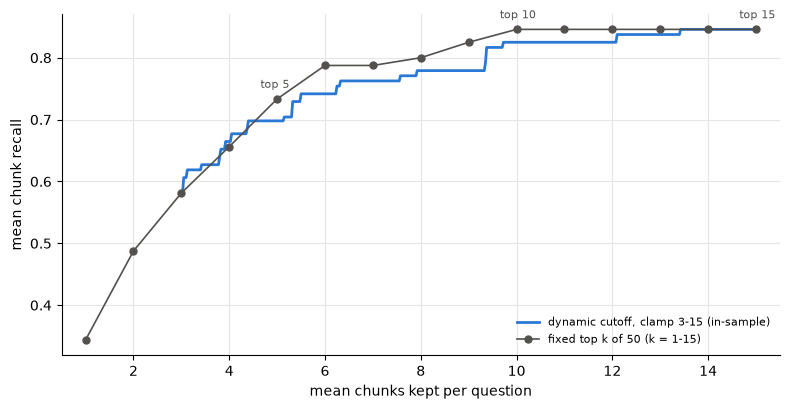

In [7]:
BLUE, ORANGE, GREY, GRID = "#2a78d6", "#eb6834", "#52514e", "#e5e5e5"


def style(ax):
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


# Lowering the cutoff never reduces any question's n, so mean chunks and recall both rise monotonically along the sweep.
dyn_curve = sweep.iloc[::-1]
# Plot dynamic and fixed-k curves
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(dyn_curve["mean chunks"], dyn_curve["chunk recall"], color=BLUE, linewidth=2,
        label="dynamic cutoff, clamp 3-15 (in-sample)")
ax.plot(fixed.index, fixed["chunk recall"], color=GREY, linewidth=1.2, marker="o", markersize=5,
        label="fixed top k of 50 (k = 1-15)")
# Label top 5, 10 and 15
for k in (5, 10, 15):
    ax.annotate(f"top {k}", (k, fixed.loc[k, "chunk recall"]), xytext=(-12, 8), textcoords="offset points",
                fontsize=8, color=GREY)
# Axis labels, limits and legend
ax.set_xlabel("mean chunks kept per question")
ax.set_ylabel("mean chunk recall")
ax.set_xlim(0.5, 15.5)
ax.legend(frameon=False, fontsize=8, loc="lower right")
style(ax)
fig.tight_layout()

## Equal-budget comparison, in-sample

For each budget k, the dynamic point is the cutoff with the best in-sample recall at mean chunks ≤ k (ties: fewer
mean chunks, then higher cutoff). It is compared two ways:
- with **fixed top k**, which keeps exactly k (so the dynamic side may use slightly fewer chunks);
- with **fixed k at exactly the same mean chunks**: when the dynamic point averages m chunks with
  k₀ < m < k₀ + 1, the fixed side keeps k₀ for a share (1 − (m − k₀)) of questions and k₀ + 1 for the rest, which in
  expectation is linear interpolation between top k₀ and top k₀ + 1.

**Which budgets are meaningful.** If most questions sit on a clamp, the dynamic rule is mostly "top 3" or "top 15"
and the comparison says nothing about the cutoff. A row is flagged *not meaningful* when more than half of the
questions are at the floor (3) or more than half at the cap (15). Budgets 3 and 15 are identical to fixed top 3 and
top 15 by construction.

In [8]:
TOL = 1e-9


def best_under_budget(rec, chunks, cutoffs, budget):
    # Index of the best cutoff: highest recall with mean chunks <= budget; ties: fewer mean chunks, then higher cutoff.
    ok = np.flatnonzero(chunks <= budget + TOL)
    rec_r = np.round(rec[ok] / TOL) * TOL  # recall equal within 1e-9 counts as a tie
    order = np.lexsort((-cutoffs[ok], chunks[ok], -rec_r))
    return ok[order[0]]


def fixed_at(m, rows=ROWS):
    # Per-question recall of fixed k at mean chunks exactly m (expected value of mixing top floor(m) and top ceil(m)).
    k0 = int(np.floor(m + TOL))
    w = m - k0
    return RECALL[rows, k0] if w < TOL else (1 - w) * RECALL[rows, k0] + w * RECALL[rows, k0 + 1]


# Sweep metrics as arrays
rec_all, chunks_all = sweep["chunk recall"].to_numpy(), sweep["mean chunks"].to_numpy()
budget_rows = []
for k in range(3, 16):
    # Best cutoff under this budget
    i = best_under_budget(rec_all, chunks_all, CUTOFFS, k)
    m = chunks_all[i]
    # Floor and cap shares
    floor_share, cap_share = (N_ALL[i] == MIN_KEEP).mean(), (N_ALL[i] == MAX_KEEP).mean()
    # Row of dynamic against fixed results
    budget_rows.append({"budget k": k, "cutoff": CUTOFFS[i], "dynamic mean chunks": m,
                        "dynamic recall": rec_all[i], "top k recall": RECALL[:, k].mean(),
                        "fixed recall at same mean": fixed_at(m).mean(),
                        "diff vs top k": rec_all[i] - RECALL[:, k].mean(),
                        "diff at same mean": rec_all[i] - fixed_at(m).mean(),
                        "share at floor": floor_share, "share at cap": cap_share,
                        "meaningful": k not in (MIN_KEEP, MAX_KEEP) and floor_share <= 0.5 and cap_share <= 0.5})
# Budget table
in_sample_budgets = pd.DataFrame(budget_rows).set_index("budget k")
in_sample_budgets.round(3)

,cutoff,dynamic mean chunks,dynamic recall,top k recall,fixed recall at same mean,diff vs top k,diff at same mean,share at floor,share at cap,meaningful
budget k,,,,,,,,,,
3,7.538,3.000,0.581,0.581,0.581,0.000,0.000,1.000,0.000,False
4,0.957,3.925,0.665,0.656,0.651,0.008,0.014,0.725,0.000,False
5,0.510,4.400,0.698,0.733,0.687,-0.035,0.011,0.675,0.025,False
6,-0.616,5.500,0.742,0.788,0.760,-0.046,-0.019,0.550,0.075,False
7,-1.220,6.325,0.762,0.788,0.788,-0.025,-0.025,0.425,0.125,True
8,-2.691,7.925,0.779,0.800,0.799,-0.021,-0.020,0.300,0.250,True
9,-2.691,7.925,0.779,0.825,0.799,-0.046,-0.020,0.300,0.250,True
10,-3.898,9.725,0.825,0.846,0.840,-0.021,-0.015,0.200,0.400,True
11,-3.898,9.725,0.825,0.846,0.840,-0.021,-0.015,0.200,0.400,True


## The selection rule (stated before any cross-validated result)

This rule was written before any cross-validated number in this notebook was computed, and is not changed after.

**Rule.** From the cutoff grid (midpoints between consecutive distinct observed MiniLM scores of the questions
available for tuning, plus one 1.0 below the lowest and one 1.0 above the highest), choose the cutoff with the
**highest mean chunk recall subject to mean chunks kept ≤ 10**, with the 3–15 clamp applied per question. Break
ties by **fewer mean chunks**, then by the **higher cutoff**. Recall values that differ by less than 1e-9 count as
tied (floating-point noise in averaging fractions).

**Why ≤ 10:** the frozen cutoff will run against the top-10 system in the final end-to-end comparison, so it gets the
same context budget on average.

**Is it well-posed?** I checked for a concrete problem before running cross-validation and found none that requires a
change: the feasible set is never empty (high cutoffs give a mean of 3 chunks), and the tie-breaks make the choice
unique. Two implementation details are fixed here because the brief leaves them open:
- the grid is built from the *tuning questions'* scores only (in cross-validation, the training folds), so no
  held-out information enters the choice;
- the tie-break "higher cutoff" picks the top gap among cutoffs that select identically on the tuning questions. That
  puts the cutoff next to the next observed score above it, so it is not the most robust point in its tie region.
  The brief specifies it and it is a legitimate tie-break, so it is kept; the sensitivity check after freezing shows
  what moving it would do.

**Cross-validation protocol (also fixed now).**
- Repeated 5-fold cross-validation: 20 repeats with seeds 0–19 (`np.random.default_rng(seed).permutation(40)`, split
  into 5 folds of 8). In each fold, the rule is applied to the 32 training questions only, and the chosen cutoff
  is scored on the 8 held-out questions. Each repeat pools its 40 held-out results into one recall and one mean
  chunks; the spread is over the 20 repeats.
- The same procedure with the budget 10 replaced by B ∈ {6, 8, 10, 12} gives the cross-validated curve. B = 10 is
  the rule itself.
- **Equal-budget test against fixed k.** For each repeat, the held-out mean chunks m is matched by fixed k at exactly
  m (the interpolation above). The per-question paired difference (dynamic − fixed) is averaged over the 20 repeats,
  and its 95% interval is a bootstrap over questions (10,000 resamples, seed 1). The difference against plain top B
  is reported too.
- Verdict per budget: dynamic "beats" fixed k only if the 95% interval of the equal-mean difference is above zero.

In [9]:
# Rule budget, folds and description
RULE_BUDGET = 10
BUDGETS = (6, 8, 10, 12)
REPEATS, FOLDS = 20, 5
RULE_TEXT = ("Choose the cutoff with the highest mean chunk recall subject to mean chunks kept <= 10 (clamp 3-15 "
             "applied per question), over a grid of midpoints between consecutive distinct observed MiniLM scores "
             "of the tuning questions (plus one 1.0 below the lowest and one 1.0 above the highest). Break ties by "
             "fewer mean chunks, then by the higher cutoff; recalls within 1e-9 count as tied.")


def choose_cutoff(train_rows, budget=RULE_BUDGET):
    # Apply the rule using only the questions in train_rows. Returns the chosen cutoff.
    grid = cutoff_grid(SCORES[train_rows])
    n = kept(grid, train_rows)
    rec = RECALL[train_rows[None, :], n].mean(1)
    return grid[best_under_budget(rec, n.mean(1), grid, budget)]

## Cross-validation

In [10]:
# Cross-validate each budget across repeats
cv_n = {b: np.zeros((REPEATS, len(IDS)), int) for b in BUDGETS}   # held-out chunks kept, per repeat and question
cv_cut = {b: [] for b in BUDGETS}
for seed in range(REPEATS):
    # Random folds for this repeat
    folds = np.array_split(np.random.default_rng(seed).permutation(len(IDS)), FOLDS)
    for test in folds:
        # Tune on the training folds
        train = np.setdiff1d(ROWS, test)
        for b in BUDGETS:
            # Choose a cutoff and score the held-out questions
            c = choose_cutoff(train, b)
            cv_n[b][seed, test] = kept([c], test)[0]
            cv_cut[b].append(c)

# Held-out recall per repeat
cv_rec = {b: RECALL[ROWS[None, :], cv_n[b]] for b in BUDGETS}   # (repeats, 40)


def spread(x):
    return f"{x.mean():.3f} (sd {x.std(ddof=1):.3f}, range {x.min():.3f}-{x.max():.3f})"


# Cross-validated summary for the rule
cv_rule = pd.Series({"chunk recall": spread(cv_rec[RULE_BUDGET].mean(1)),
                     "mean chunks": spread(cv_n[RULE_BUDGET].mean(1)),
                     "all chunks found": spread((cv_rec[RULE_BUDGET] == 1).mean(1))},
                    name="rule (budget 10), held-out, 20 repeats x 5 folds").to_frame()
# Report cutoffs chosen across folds
cuts = np.array(cv_cut[RULE_BUDGET])
print(f"cutoffs chosen across the 100 training folds: min {cuts.min():.2f}, median {np.median(cuts):.2f}, "
      f"max {cuts.max():.2f}")
cv_rule

cutoffs chosen across the 100 training folds: min -3.91, median -3.90, max -2.34


,"rule (budget 10), held-out, 20 repeats x 5 folds"
chunk recall,"0.809 (sd 0.013, range 0.779-0.817)"
mean chunks,"9.525 (sd 0.145, range 9.150-9.700)"
all chunks found,"0.689 (sd 0.019, range 0.650-0.700)"


### Cross-validated curve and equal-budget comparison

For each budget B, the held-out results against fixed k. "Fixed k at same mean" uses, per repeat, the held-out mean
chunks of that repeat.

In [11]:
# Fixed bootstrap resample indices
boot_rng = np.random.default_rng(1)
BOOT_IDX = boot_rng.integers(0, len(IDS), (10_000, len(IDS)))


def boot_ci(d):
    means = d[BOOT_IDX].mean(1)
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


# Table rows per budget
cv_rows = []
for b in BUDGETS:
    m_rep = cv_n[b].mean(1)                                               # held-out mean chunks per repeat
    base_same = np.stack([fixed_at(m) for m in m_rep])                    # (repeats, 40)
    d_same = (cv_rec[b] - base_same).mean(0)                              # per-question, averaged over repeats
    d_topb = (cv_rec[b] - RECALL[:, b][None, :]).mean(0)
    # Bootstrap intervals
    lo, hi = boot_ci(d_same)
    lo_b, hi_b = boot_ci(d_topb)
    q_rec = cv_rec[b].mean(0)
    # Row for this budget
    cv_rows.append({
        "budget B": b, "CV recall": cv_rec[b].mean(), "CV recall sd": cv_rec[b].mean(1).std(ddof=1),
        "CV mean chunks": m_rep.mean(), "CV chunks sd": m_rep.std(ddof=1),
        "fixed at same mean": base_same.mean(), "diff at same mean": d_same.mean(),
        "95% CI (same mean)": f"{lo:+.3f} to {hi:+.3f}",
        "top B recall": RECALL[:, b].mean(), "diff vs top B": d_topb.mean(),
        "95% CI (vs top B)": f"{lo_b:+.3f} to {hi_b:+.3f}",
        "questions better / same / worse vs top B": f"{(q_rec > RECALL[:, b] + TOL).sum()} / "
            f"{(abs(q_rec - RECALL[:, b]) <= TOL).sum()} / {(q_rec < RECALL[:, b] - TOL).sum()}",
        "beats fixed at same mean?": "yes" if lo > 0 else ("no, worse" if hi < 0 else "no clear difference"),
    })
# Assemble the comparison table
cv_table = pd.DataFrame(cv_rows).set_index("budget B")
cv_table.round(3)

,CV recall,CV recall sd,CV mean chunks,CV chunks sd,fixed at same mean,diff at same mean,95% CI (same mean),top B recall,diff vs top B,95% CI (vs top B),questions better / same / worse vs top B,beats fixed at same mean?
budget B,,,,,,,,,,,,
6,0.731,0.012,5.709,0.184,0.772,-0.041,-0.118 to +0.030,0.788,-0.057,-0.135 to +0.017,2 / 29 / 9,no clear difference
8,0.764,0.006,7.625,0.158,0.795,-0.031,-0.108 to +0.039,0.800,-0.036,-0.110 to +0.028,2 / 32 / 6,no clear difference
10,0.809,0.013,9.525,0.145,0.836,-0.027,-0.066 to +0.007,0.846,-0.036,-0.073 to -0.007,0 / 34 / 6,no clear difference
12,0.818,0.003,10.865,0.312,0.846,-0.028,-0.062 to +0.000,0.846,-0.028,-0.062 to +0.000,0 / 37 / 3,no clear difference


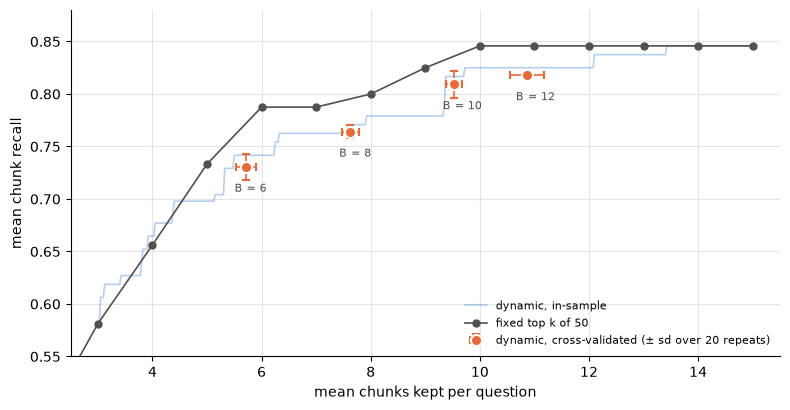

In [12]:
# Plot in-sample and fixed-k curves
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(dyn_curve["mean chunks"], dyn_curve["chunk recall"], color=BLUE, linewidth=1.2, alpha=0.35,
        label="dynamic, in-sample")
ax.plot(fixed.index, fixed["chunk recall"], color=GREY, linewidth=1.2, marker="o", markersize=5,
        label="fixed top k of 50")
# Mean and sd of cross-validated points
x = [cv_n[b].mean(1).mean() for b in BUDGETS]
y = [cv_rec[b].mean(1).mean() for b in BUDGETS]
xerr = [cv_n[b].mean(1).std(ddof=1) for b in BUDGETS]
yerr = [cv_rec[b].mean(1).std(ddof=1) for b in BUDGETS]
# Plot cross-validated points with error bars
ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt="o", color=ORANGE, markersize=8, capsize=3, linewidth=1.2,
            markeredgecolor="white", markeredgewidth=1.5, zorder=3,
            label="dynamic, cross-validated (± sd over 20 repeats)")
# Label each budget
for b, xi, yi in zip(BUDGETS, x, y):
    ax.annotate(f"B = {b}", (xi, yi), xytext=(-8, -18), textcoords="offset points", fontsize=8, color=GREY)
# Axis labels, limits and legend
ax.set_xlabel("mean chunks kept per question")
ax.set_ylabel("mean chunk recall")
ax.set_xlim(2.5, 15.5)
ax.set_ylim(0.55, 0.88)
ax.legend(frameon=False, fontsize=8, loc="lower right")
style(ax)
fig.tight_layout()

## Freeze: apply the rule to all 40 questions

Standard practice: select on all the data with the stated rule, and report the cross-validated number as the honest
estimate of how it performs. The JSON is written only if it doesn't exist yet; if it does, the notebook checks that
it would freeze the same cutoff and leaves the file alone.

In [13]:
# Apply the rule to all 40 questions
CUTOFF_EXACT = choose_cutoff(ROWS, RULE_BUDGET)
FROZEN_CUTOFF = round(float(CUTOFF_EXACT), 4)
# Check rounding keeps the selection
n_frozen = kept([FROZEN_CUTOFF])[0]
assert (n_frozen == kept([CUTOFF_EXACT])[0]).all(), "rounding the cutoff changed the selection"
# In-sample recall and mean chunks
in_rec, in_chunks = RECALL[ROWS, n_frozen].mean(), n_frozen.mean()
# Report frozen cutoff and top 10 references
print(f"frozen cutoff {FROZEN_CUTOFF} -> in-sample recall {in_rec:.3f}, mean chunks {in_chunks:.3f}, "
      f"median {np.median(n_frozen):.1f}, at floor {int((n_frozen == 3).sum())}, at cap {int((n_frozen == 15).sum())}")
print(f"fixed top 10 of 50: recall {RECALL[:, 10].mean():.3f}; top 10 of 30 (app): {RECALL30[:, 10].mean():.3f}")

frozen cutoff -3.898 -> in-sample recall 0.825, mean chunks 9.725, median 11.0, at floor 8, at cap 16
fixed top 10 of 50: recall 0.846; top 10 of 30 (app): 0.846


### Where the frozen cutoff differs from top 10, per question

Questions whose recall under the frozen cutoff differs from fixed top 10 (both from the same 50 reranked
candidates), with how many items the cutoff keeps and the question's top MiniLM score.

In [14]:
# Per-question comparison with top 10
diff_q = pd.DataFrame({"type": TYPES, "top score": SCORES[:, 0], "frozen n": n_frozen,
                       "frozen recall": RECALL[ROWS, n_frozen], "top 10 recall": RECALL[:, 10],
                       "top 10 of 30 recall": RECALL30[:, 10]}, index=IDS)
# Keep questions that differ
diff_q = diff_q[diff_q["frozen recall"] != diff_q["top 10 recall"]]
# Count better and worse
print("better than top 10:", int((diff_q["frozen recall"] > diff_q["top 10 recall"]).sum()),
      "| worse:", int((diff_q["frozen recall"] < diff_q["top 10 recall"]).sum()))
diff_q.round(2)

better than top 10: 0 | worse: 2


,type,top score,frozen n,frozen recall,top 10 recall,top 10 of 30 recall
A-12,multi-article,-5.61,3,0.33,0.67,0.67
C1-07,multi-article,0.05,3,0.50,1.00,1.00


In [15]:
# Why top 11-15 of 50 is worse than top 11-15 of 30: how many of the first 15 reranked items came from fused ranks 31-50.
# Late fused items in the top 15
late = np.array([(ranked[i]["fused rank"].to_numpy()[:15] > 30).sum() for i in IDS])
# Expected chunks per question
expected_items = {q.id: set().union(*ev.expected_chunks(q)) for q in questions}
late_hits = sum(bool(set(ranked[i][ranked[i]["fused rank"] > 30]["item"]) & expected_items[i]) for i in IDS)
# Report late-item counts
print(f"items from fused ranks 31-50 inside the top 15 after reranking: mean {late.mean():.2f} per question, "
      f"{(late > 0).sum()} of 40 questions have at least one")
print(f"questions with an expected chunk among fused ranks 31-50: {late_hits}")

items from fused ranks 31-50 inside the top 15 after reranking: mean 1.98 per question, 31 of 40 questions have at least one
questions with an expected chunk among fused ranks 31-50: 1


### How sensitive is it?

Nearby cutoffs, in-sample. The tie-break puts the cutoff at the upper edge of its tie region.

In [16]:
# Nearby cutoffs and their kept counts
nearby = FROZEN_CUTOFF + np.array([-1.0, -0.5, -0.25, -0.1, 0.0, 0.1, 0.25, 0.5, 1.0])
nb_n = kept(nearby)
# Metrics at nearby cutoffs
pd.DataFrame({"cutoff": nearby, "chunk recall": RECALL[ROWS, nb_n].mean(1), "mean chunks": nb_n.mean(1),
              "mean tokens": TOKENS[ROWS, nb_n].mean(1)}).set_index("cutoff").round(3)

,chunk recall,mean chunks,mean tokens
cutoff,,,
-4.898,0.825,10.825,5705.925
-4.398,0.825,10.400,5477.500
-4.148,0.825,10.075,5312.775
-3.998,0.825,9.775,5143.400
-3.898,0.825,9.725,5119.625
-3.798,0.817,9.600,5054.100
-3.648,0.779,9.325,4899.275
-3.398,0.779,9.125,4794.775
-2.898,0.779,8.400,4418.125


In [17]:
# Cross-validated rule metrics
cv_r, cv_c = cv_rec[RULE_BUDGET].mean(1), cv_n[RULE_BUDGET].mean(1)
row10 = cv_table.loc[RULE_BUDGET]
# Assemble the frozen-rule record
frozen = {
    "model": r.rerank_model,
    "score": "raw MiniLM cross-encoder logit on (question, item text), as Reranker.score returns it",
    "candidates_reranked": N_CAND,
    "first_stage": {"dense_candidates": r.candidates, "bm25_candidates": r.candidates, "rrf_k": r.rrf_k},
    "cutoff": FROZEN_CUTOFF,
    "selection": "keep every reranked candidate with score >= cutoff, best first",
    "min_kept": MIN_KEEP,
    "max_kept": MAX_KEEP,
    "rule": RULE_TEXT,
    "in_sample": {"questions": len(IDS), "chunk_recall": round(float(in_rec), 4), "mean_chunks": round(float(in_chunks), 3)},
    "cross_validated": {
        "protocol": "repeated 5-fold, 20 repeats (seeds 0-19), rule applied on training folds only",
        "chunk_recall": round(float(cv_r.mean()), 4), "chunk_recall_sd_over_repeats": round(float(cv_r.std(ddof=1)), 4),
        "mean_chunks": round(float(cv_c.mean()), 3), "mean_chunks_sd_over_repeats": round(float(cv_c.std(ddof=1)), 3),
        "diff_vs_fixed_k_at_same_mean_chunks": round(float(row10["diff at same mean"]), 4),
        "diff_vs_fixed_k_95ci_bootstrap_over_questions": row10["95% CI (same mean)"],
    },
    "reference_fixed_top10": {"of_50_reranked": round(float(RECALL[:, 10].mean()), 4),
                              "of_30_reranked_app_default": round(float(RECALL30[:, 10].mean()), 4)},
    "eval_set": "evals/handbook_eval.jsonl",
    "notebook": "notebooks/09b_dynamic_selection_50.ipynb",
    "date": date.today().isoformat(),
    "note": "frozen before the final end-to-end comparison; must not be changed after seeing those results",
}
# Write the file unless already frozen
FROZEN_PATH = ROOT / "evals" / "frozen_dynamic_selection.json"
if FROZEN_PATH.exists():
    existing = json.loads(FROZEN_PATH.read_text(encoding="utf-8"))
    assert existing["cutoff"] == FROZEN_CUTOFF, "re-run disagrees with the frozen cutoff; investigate, don't overwrite"
    print("already frozen; file left unchanged")
else:
    FROZEN_PATH.write_text(json.dumps(frozen, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    print("wrote", FROZEN_PATH.relative_to(ROOT))
# Print the saved file
print(json.dumps(json.loads(FROZEN_PATH.read_text(encoding="utf-8")), indent=2, ensure_ascii=False))

already frozen; file left unchanged
{
  "model": "Xenova/ms-marco-MiniLM-L-6-v2",
  "score": "raw MiniLM cross-encoder logit on (question, item text), as Reranker.score returns it",
  "candidates_reranked": 50,
  "first_stage": {
    "dense_candidates": 50,
    "bm25_candidates": 50,
    "rrf_k": 60
  },
  "cutoff": -3.898,
  "selection": "keep every reranked candidate with score >= cutoff, best first",
  "min_kept": 3,
  "max_kept": 15,
  "rule": "Choose the cutoff with the highest mean chunk recall subject to mean chunks kept <= 10 (clamp 3-15 applied per question), over a grid of midpoints between consecutive distinct observed MiniLM scores of the tuning questions (plus one 1.0 below the lowest and one 1.0 above the highest). Break ties by fewer mean chunks, then by the higher cutoff; recalls within 1e-9 count as tied.",
  "in_sample": {
    "questions": 40,
    "chunk_recall": 0.825,
    "mean_chunks": 9.725
  },
  "cross_validated": {
    "protocol": "repeated 5-fold, 20 repeats (

## Conclusions

**Frozen cutoff: −3.898** on MiniLM's raw score, over the top 50 fused candidates, keeping 3–15 items. It was chosen
by the rule stated above (highest recall at mean chunks ≤ 10; ties by fewer chunks, then higher cutoff), applied to
all 40 questions. Saved in `evals/frozen_dynamic_selection.json`.

| | chunk recall | mean chunks |
|---|---|---|
| fixed top 10 of 50 (and of 30, the app's pool) | 0.846 | 10 |
| frozen cutoff, in-sample | 0.825 | 9.73 |
| frozen rule, 5-fold CV × 20 repeats | 0.809 (sd 0.013, range 0.779–0.817) | 9.53 (sd 0.15) |
| fixed k at the same mean chunks (9.53) | 0.836 | 9.53 |

**Cross-validated, equal average chunks** (paired difference dynamic − fixed k, averaged over repeats; 95% bootstrap
interval over questions):

| budget B | CV mean chunks | CV recall | fixed k at same mean | difference | 95% interval | vs plain top B |
|---|---|---|---|---|---|---|
| 6 | 5.71 | 0.731 | 0.772 | −0.041 | −0.118 to +0.030 | −0.057 (−0.135 to +0.017) |
| 8 | 7.63 | 0.764 | 0.795 | −0.031 | −0.108 to +0.039 | −0.036 (−0.110 to +0.028) |
| 10 | 9.53 | 0.809 | 0.836 | −0.027 | −0.066 to +0.007 | −0.036 (−0.073 to −0.007) |
| 12 | 10.87 | 0.818 | 0.846 | −0.028 | −0.062 to +0.000 | −0.028 (−0.062 to +0.000) |

What the numbers say:

- **Dynamic selection is not better than fixed k at the same average number of chunks.** At every budget the
  cross-validated point lies below the fixed-k curve, by 0.03–0.04 recall. None of the intervals is entirely above
  zero. Most of them include zero, so a small loss can't be told apart from no difference with 40 questions. Against
  plain top 10 the rule is worse (−0.036, interval −0.073 to −0.007): 6 questions worse, 34 the same and none better.
- **Even in-sample it doesn't beat fixed k.** The in-sample dynamic curve sits on or below the fixed-k line from
  about 5.3 to 15 chunks: 0.825 against 0.846 at the rule's budget. It edges above (by 0.01–0.02) only below about
  5 chunks, where two-thirds or more of the questions are pinned at the floor of 3.
- **Budgets where the comparison isn't meaningful.** In-sample, at budgets 3–6 more than half of the questions sit
  at the floor of 3. At 13–15 more than half sit at the cap of 15, so the rule is mostly fixed top 3 or top 15 there.
  B = 6 was still cross-validated because it was in the plan, but it is mostly a test of the floor. B = 12 lands at
  10.9 mean chunks, not 12. Recall is flat between about 9.7 and 12 chunks, so the tie-break toward fewer chunks
  often picks the same cutoff as B = 10.
- **Why it loses.** The floor of 3 causes the losses: under the frozen cutoff, A-12 and C1-07 (both multi-article,
  low top scores) keep only 3 items and lose a chunk that top 10 finds. In notebook 09 the cap of 15 brought the
  gains (A-01, C1-04 had a chunk at rank 11–15). With 50 candidates that gain is gone: candidates from fused ranks
  31–50 add no expected chunk (recall with all 50 kept equals recall with all 30, 0.900), but they push about 2
  items per question into the top 15. So top 15 of 50 recalls 0.846, against 0.879 for top 15 of 30.
- **The rule is stable but the cutoff sits at a step.** Across the 100 training folds the chosen cutoff had a median
  of −3.90 (range −3.91 to −2.34), close to the frozen −3.898 and to notebook 09's −3.68. In-sample, raising it by
  0.1 drops recall to 0.817 and by 0.25 to 0.779.
- **Reranking 50 instead of 30 gains nothing here.** Fixed top k of 50 is at or below top k of 30 at every k, and the
  first stage plus MiniLM takes longer per question (median 4.9 s here against 3.25 s for 30 candidates in
  notebook 09).

**For the final end-to-end comparison:** the frozen cutoff runs as specified in the JSON. The cross-validated
estimate of its retrieval (0.809 recall at 9.5 chunks) is the honest number, and it is expected to come out slightly
below top 10 on retrieval. The cutoff must not be changed after seeing the end-to-end results.